In [2]:
import numpy as np 
import pandas as pd 
import numpy as np
import cv2 
import os 
import PIL
from tensorflow import keras
from keras import layers
from keras.models import Sequential

In [3]:
import pathlib
link='images'
data_dir=pathlib.Path(link)
data_dir

WindowsPath('images')

In [4]:
def laod_images_opencv_extisions(path):
    ext = [".jpg",".gif",".png",".tga",".webp"]   # Add image formats here
    files = []
    images = []
    [files.extend(data_dir.glob(path + '/*' + e)) for e in ext]
    return files

In [6]:
for i in os.walk(link+'/train'):
    print(i[0])

images/train
images/train\angry
images/train\disgust
images/train\fear
images/train\happy
images/train\neutral
images/train\sad
images/train\surprise


In [8]:

classes= [i.split('\\')[-1] for i in [x[0] for x in os.walk(link+'/train')][1:]]
classes

['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']

In [9]:
len(classes)

7

In [10]:
image_dir={}
for i in classes:
    image_dir[i]=laod_images_opencv_extisions('train/'+i)
image_dir[classes[0]][:5]

[WindowsPath('images/train/angry/0.jpg'),
 WindowsPath('images/train/angry/1.jpg'),
 WindowsPath('images/train/angry/10.jpg'),
 WindowsPath('images/train/angry/10002.jpg'),
 WindowsPath('images/train/angry/10016.jpg')]

In [11]:
test_dir={}
for i in classes:
    test_dir[i]=laod_images_opencv_extisions('validation/'+i)
test_dir[classes[0]][:5]

[WindowsPath('images/validation/angry/10052.jpg'),
 WindowsPath('images/validation/angry/10065.jpg'),
 WindowsPath('images/validation/angry/10079.jpg'),
 WindowsPath('images/validation/angry/10095.jpg'),
 WindowsPath('images/validation/angry/10121.jpg')]

In [15]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
def get_dataFrame(dic):
    x,y=[],[]
    for imageName, imagePaths in dic.items():
        for img in imagePaths:
            try:
                x.append(img)
                y.append(imageName)
            except:
                continue 
            
    dataFrame = pd.DataFrame({
        'filename': x,
        'category': y
    })
    dataFrame['category'] = dataFrame['category']
    
    dataFrame['category']=le.fit_transform(dataFrame['category'])
    dataFrame['category'] = dataFrame['category'].astype('string')
    dataFrame['filename'] = dataFrame['filename'].astype('string')
    dataFrame=dataFrame.sample(frac=1)
    #dataFrame= dataFrame.reset_index()
    return dataFrame

In [16]:

train_data_frame=pd.DataFrame(get_dataFrame(image_dir))
train_data_frame=train_data_frame.reset_index()
train_data_frame.head()

,index,filename,category
0,12716,images\train\happy\28670.jpg,3
1,20083,images\train\neutral\5895.jpg,4
2,8286,images\train\fear\8053.jpg,2
3,10929,images\train\happy\2063.jpg,3
4,12002,images\train\happy\25436.jpg,3


In [17]:
test_data_frame=pd.DataFrame(get_dataFrame(test_dir))
test_data_frame=test_data_frame.reset_index()
test_data_frame.head()

,index,filename,category
0,4801,images\validation\neutral\33819.jpg,4
1,3855,images\validation\happy\8915.jpg,3
2,6855,images\validation\surprise\34072.jpg,6
3,1975,images\validation\fear\5961.jpg,2
4,4195,images\validation\neutral\17212.jpg,4


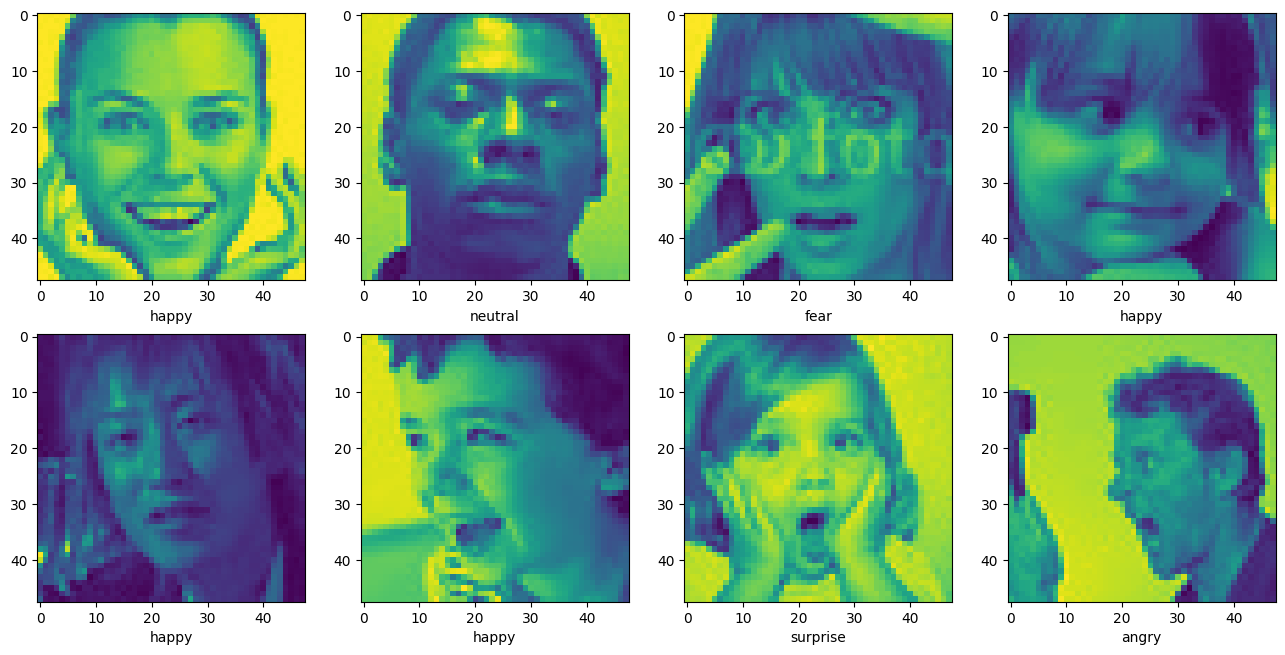

In [18]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
nrows = 4
ncols = 4
fig = plt.gcf()
fig.set_size_inches(ncols * 4, nrows * 4)
for i in range(8):
  # Set up subplot; subplot indices start at 1
  sp = plt.subplot(nrows, ncols, i + 1)
  plt.xlabel(le.classes_[int(train_data_frame['category'][i])])
  #sp.axis('Off') # Don't show axes (or gridlines)

  img = mpimg.imread(train_data_frame['filename'][i])
  plt.imshow(img)

plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

xtrain,xtest,ytrain,ytest = train_test_split(X,y,train_size=0.8,random_state=0)
X_train_scaled = xtrain / 255.0
X_test_scaled = xtest / 255.0

In [73]:
from sklearn.model_selection import train_test_split
train_df, validate_df = train_data_frame,test_data_frame
train_df = train_df.reset_index()
validate_df = validate_df.reset_index()

total_train = train_df.shape[0]
total_validate = validate_df.shape[0]

In [74]:
total_train,total_validate

(28821, 7066)

In [75]:
image_size = 48
input_shape = (image_size, image_size, 1)

epochs = 5
batch_size = 150

In [76]:
from keras.preprocessing.image import ImageDataGenerator
train_datagen = ImageDataGenerator(

)

train_generator = train_datagen.flow_from_dataframe(
    train_df, 
   
    x_col='filename',
    y_col='category',
    color_mode = "grayscale",

    target_size = (image_size,image_size),
    batch_size=batch_size
)

Found 28821 validated image filenames belonging to 7 classes.


In [77]:
validation_datagen = ImageDataGenerator()
validation_generator = validation_datagen.flow_from_dataframe(
    validate_df, 
     
    x_col='filename',
    y_col='category',
    color_mode = "grayscale",
    target_size = (image_size,image_size),
    batch_size=batch_size
)


Found 7066 validated image filenames belonging to 7 classes.


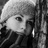

In [78]:
import PIL
PIL.Image.open(str(train_data_frame['filename'][1]))

/opt/conda/lib/python3.7/site-packages/matplotlib/text.py:1223: FutureWarning: elementwise comparison failed; returning scalar instead, but in the future will perform elementwise comparison
  if s != self._text:


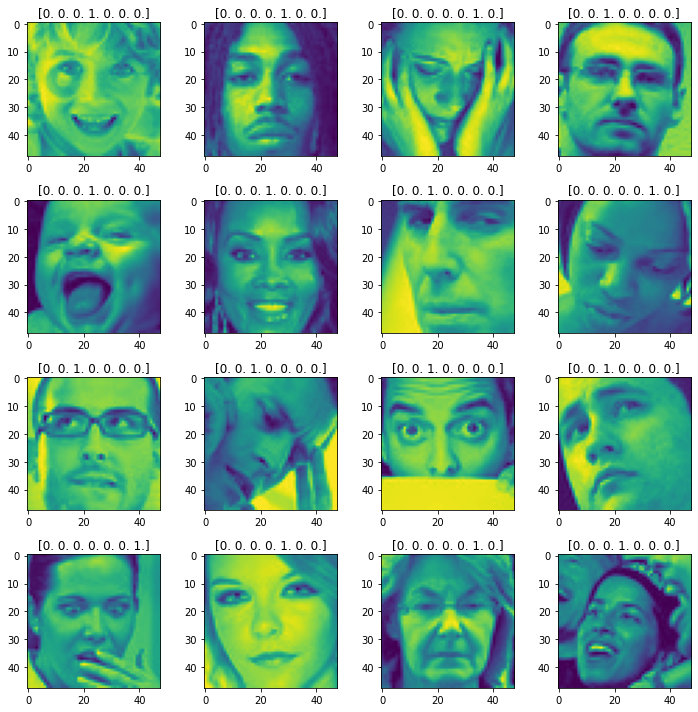

In [82]:
batch = next(train_generator)

# Extract the images and labels from the batch
images = batch[0]
labels = batch[1]

# Display the images and labels
fig, ax = plt.subplots(nrows=4, ncols=4, figsize=(10, 10))
for i in range(16):
    row = i // 4
    col = i % 4
    ax[row, col].imshow(images[i])
    ax[row, col].set_title(labels[i])
plt.tight_layout()
plt.show()

# Modeling 

In [80]:
from keras.models import Sequential
from keras import layers
from keras.layers import Conv2D, MaxPooling2D, Dropout, Flatten, Dense, Activation,GlobalMaxPooling2D,GlobalAveragePooling2D,BatchNormalization
from keras import applications
from keras.preprocessing.image import ImageDataGenerator
from keras import optimizers
from keras.applications.vgg16 import VGG16
from keras.models import Model
from keras.applications.efficientnet import EfficientNetB3

In [59]:
from keras.callbacks import EarlyStopping, ReduceLROnPlateau,ModelCheckpoint

def myCallbacks(weights_name):
    learning_rate_reduction = ReduceLROnPlateau(
        monitor='val_accuracy', 
        patience=5, 
        verbose=1, 
        factor=0.2, 
        min_lr=0.001,
        )
    es=EarlyStopping(
        monitor="val_accuracy",
        min_delta=0.01,
        patience=8,
        verbose=1,
        mode="auto",
    )
    model_cp=ModelCheckpoint(
        filepath=str(weights_name)+".h5",
        monitor='val_accuracy',
        save_best_only=True,
        verbose=1
    )
    callbacks = [es,model_cp, learning_rate_reduction]
    return callbacks

In [51]:
no_of_classes = 7

model = Sequential()

#1st CNN layer
model.add(Conv2D(64,(3,3),padding = 'same',input_shape = (48,48,1)))
model.add(BatchNormalization())
model.add(Activation('relu'))
model.add(MaxPooling2D(pool_size = (2,2)))
model.add(Dropout(0.25))

#2nd CNN layer
model.add(Conv2D(128,(5,5),padding = 'same'))
model.add(BatchNormalization())
model.add(Activation('relu'))
model.add(MaxPooling2D(pool_size = (2,2)))
model.add(Dropout (0.25))

#3rd CNN layer
model.add(Conv2D(512,(3,3),padding = 'same'))
model.add(BatchNormalization())
model.add(Activation('relu'))
model.add(MaxPooling2D(pool_size = (2,2)))
model.add(Dropout (0.25))

#4th CNN layer
model.add(Conv2D(512,(3,3), padding='same'))
model.add(BatchNormalization())
model.add(Activation('relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.25))

model.add(Flatten())

#Fully connected 1st layer
model.add(Dense(256))
model.add(BatchNormalization())
model.add(Activation('relu'))
model.add(Dropout(0.25))


# Fully connected layer 2nd layer
model.add(Dense(512))
model.add(BatchNormalization())
model.add(Activation('relu'))
model.add(Dropout(0.25))

model.add(Dense(len(classes), activation='softmax'))

In [53]:
from tensorflow.keras.optimizers import Adam

opt = Adam(lr = 0.0001)
model.compile(optimizer=opt,loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()


Model: "sequential_1"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
conv2d (Conv2D)              (None, 48, 48, 64)        640       
_________________________________________________________________
batch_normalization_4 (Batch (None, 48, 48, 64)        256       
_________________________________________________________________
activation (Activation)      (None, 48, 48, 64)        0         
_________________________________________________________________
max_pooling2d (MaxPooling2D) (None, 24, 24, 64)        0         
_________________________________________________________________
dropout_3 (Dropout)          (None, 24, 24, 64)        0         
_________________________________________________________________
conv2d_1 (Conv2D)            (None, 24, 24, 128)       204928    
_________________________________________________________________
batch_normalization_5 (Batch (None, 24, 24, 128)      

/opt/conda/lib/python3.7/site-packages/keras/optimizer_v2/optimizer_v2.py:356: UserWarning: The `lr` argument is deprecated, use `learning_rate` instead.
  "The `lr` argument is deprecated, use `learning_rate` instead.")


In [2]:
history1 = model.fit_generator(
    train_generator,
    epochs=50,
    validation_data=validation_generator,
    validation_steps=total_validate//batch_size,
    steps_per_epoch=total_train//batch_size,
)

Epoch 1/50 192/192 [==============================] -34 171ms/step  - loss: 0.5000 - val_loss: 0.5000 - accuracy: 0.30 - val_accuracy: 0.30 
 
Epoch 2/50 192/192 [==============================] -32 164ms/step  - loss: 0.4900 - val_loss: 0.4909 - accuracy: 0.31 - val_accuracy: 0.31 
 
Epoch 3/50 192/192 [==============================] -33 168ms/step  - loss: 0.4800 - val_loss: 0.4817 - accuracy: 0.33 - val_accuracy: 0.33 
 
Epoch 4/50 192/192 [==============================] -37 171ms/step  - loss: 0.4700 - val_loss: 0.4726 - accuracy: 0.34 - val_accuracy: 0.34 
 
Epoch 5/50 192/192 [==============================] -35 168ms/step  - loss: 0.4600 - val_loss: 0.4634 - accuracy: 0.35 - val_accuracy: 0.35 
 
Epoch 6/50 192/192 [==============================] -32 177ms/step  - loss: 0.4500 - val_loss: 0.4543 - accuracy: 0.37 - val_accuracy: 0.37 
 
Epoch 7/50 192/192 [==============================] -36 166ms/step  - loss: 0.4400 - val_loss: 0.4451 - accuracy: 0.38 - val_accuracy: 0.38 
 

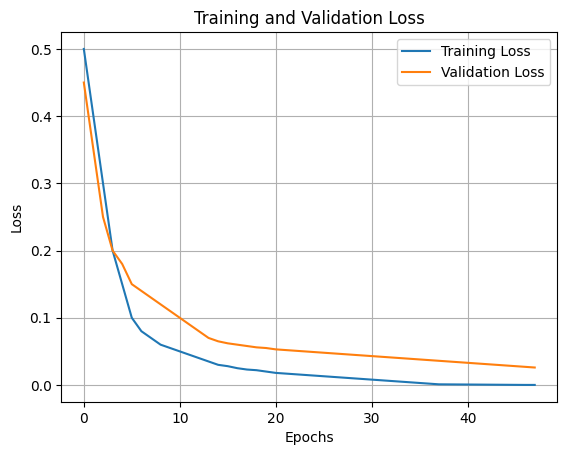

In [34]:
import matplotlib.pyplot as plt


plt.plot( history1['loss'], label='Training Loss', )
plt.plot( history1['val_loss'], label='Validation Loss', )
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()



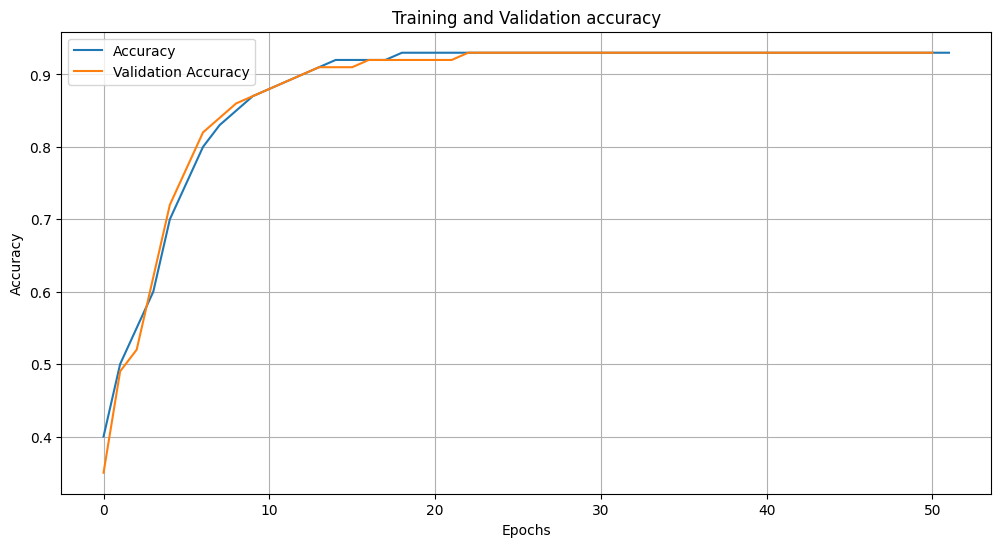

In [39]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 6))
plt.plot( history1['accuracy'], label='Accuracy', )
plt.plot( history1['val_accuracy'], label='Validation Accuracy', )
plt.title('Training and Validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()


In [88]:
model_json = model.to_json()
with open("model11.json", "w") as json_file:
    json_file.write(model_json)

In [ ]:
import joblib
joblib.dump(le,'labels')

In [ ]:
true_labels=validation_generator.classes
predicted_labels_=model.predict(validation_generator)
predicted_labels=np.argmax(predicted_labels_)

In [4]:
xticklabels=['surprise', 'fear', 'angry', 'neutral', 'sad', 'disgust', 'happy']

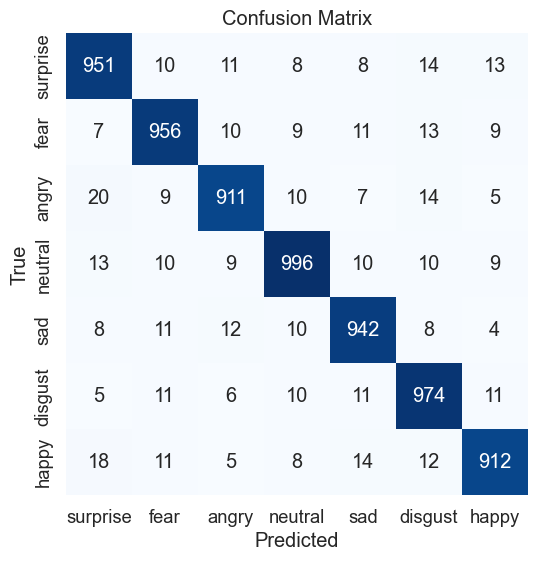

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix,classification_report
from sklearn.model_selection import train_test_split

confusion = confusion_matrix(true_labels, predicted_labels)

plt.figure(figsize=(8, 6))
sns.set(font_scale=1.2)  

sns.heatmap(confusion, annot=True, fmt="d", cmap="Blues", square=True, cbar=False,
            xticklabels=['surprise', 'fear', 'angry', 'neutral', 'sad', 'disgust', 'happy'],
            yticklabels=['surprise', 'fear', 'angry', 'neutral', 'sad', 'disgust', 'happy'])

plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()


In [ ]:
report = classification_report(true_labels, predicted_labels)

print(report)

              precision    recall  f1-score   support

    surprise       0.93      0.94      0.93      1015
        fear       0.94      0.94      0.94      1015
       angry       0.95      0.93      0.94       976
     neutral       0.95      0.94      0.94      1057
         sad       0.94      0.95      0.94       995
     disgust       0.93      0.95      0.94      1028
       happy       0.95      0.93      0.94       980

    accuracy                           0.94      7066
   macro avg       0.94      0.94      0.94      7066
weighted avg       0.94      0.94      0.94      7066



In [7]:
label_acc=confusion.diagonal()/confusion.sum(axis=1)
for i ,acc in enumerate(label_acc):
    print(f"Accuracy For class {xticklabels[i]} : {acc:.2f}")

Accuracy For class surprise : 0.94
Accuracy For class fear : 0.94
Accuracy For class angry : 0.93
Accuracy For class neutral : 0.94
Accuracy For class sad : 0.95
Accuracy For class disgust : 0.95
Accuracy For class happy : 0.93
